In [1]:
import scanpy as sc
adata = sc.read_h5ad("AS4_2.cellbin_1.0.h5ad")
adata

/home/gaokc/miniconda3/envs/omicverse/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


AnnData object with n_obs × n_vars = 25485 × 28278
    obs: 'dnbCount', 'area', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'leiden', 'orig.ident', 'x', 'y'
    var: 'real_gene_name', 'n_cells', 'n_counts', 'mean_umi', 'means', 'dispersions', 'dispersions_norm', 'highly_variable'
    uns: 'bin_size', 'bin_type', 'coded_cell_block', 'gene_exp_leiden', 'hvg', 'key_record', 'leiden_resolution', 'merged', 'neighbors', 'omics', 'pca_variance_ratio', 'rank_genes_groups', 'resolution', 'result_keys', 'sn'
    obsm: 'X_pca', 'X_umap', 'cell_border', 'spatial'
    layers: 'log1p'
    obsp: 'connectivities', 'distances'

In [2]:
adata.obs['leiden'].nunique()


23

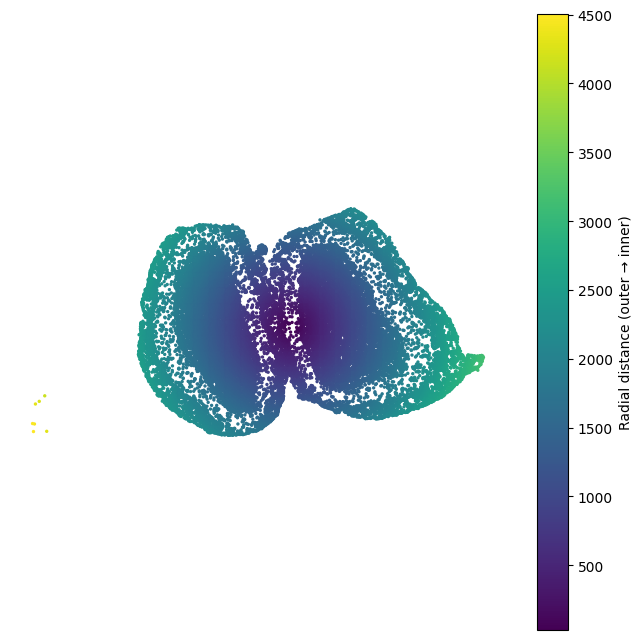

In [3]:
import numpy as np
import matplotlib.pyplot as plt

xy = adata.obsm["spatial"]
center = xy.mean(axis=0)
radial = np.linalg.norm(xy - center, axis=1)

plt.figure(figsize=(8, 8))
plt.scatter(xy[:, 0], xy[:, 1], c=radial, s=2, cmap="viridis")
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.colorbar(label="Radial distance (outer → inner)")
plt.axis("off")
plt.show()


In [4]:
adata.obs["leiden"] = adata.obs["leiden"].astype(str)
print("Leiden clusters:", adata.obs["leiden"].unique())
print(adata.obs["leiden"].value_counts().sort_index())


Leiden clusters: ['7' '6' '3' '5' '9' '8' '1' '2' '4' '16' '11' '10' '12' '14' '15' '20'
 '22' '13' '17' '18' '21' '19' '23']
leiden
1     4366
10     496
11     353
12     211
13     156
14     115
15      74
16      54
17      48
18      40
19      38
2     4100
20      34
21      32
22      32
23      29
3     3853
4     3531
5     2662
6     2616
7     1313
8      799
9      533
Name: count, dtype: int64


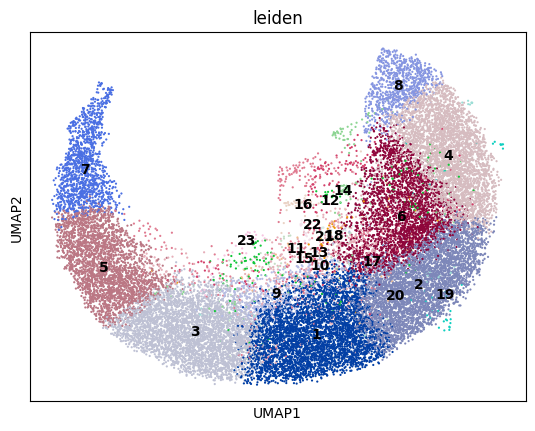

In [5]:
import scanpy as sc

sc.pl.umap(
    adata,
    color="leiden",
    legend_loc="on data",   # 或 "right margin"
    size=10
)


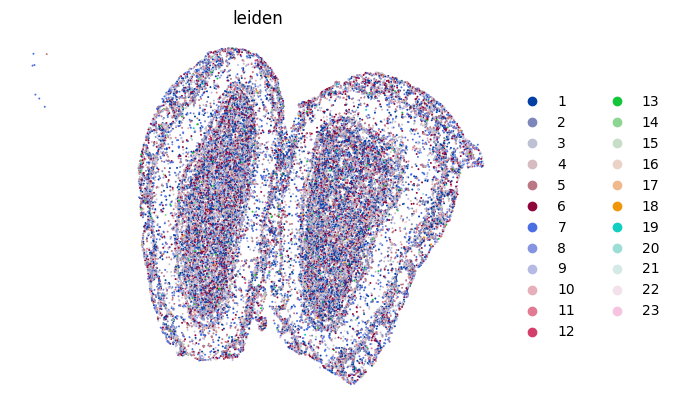

In [6]:
sc.pl.embedding(
    adata,
    basis="spatial",
    color="leiden",
    size=8,
    frameon=False
)


In [7]:
import numpy as np
import pandas as pd

gene_symbol = adata.var["real_gene_name"]

gene_symbol = gene_symbol.astype(str)

mask = gene_symbol.notna() & (gene_symbol != "nan") & (gene_symbol != "") & (gene_symbol != "None")
adata = adata[:, mask].copy()

adata.var["gene_symbol"] = gene_symbol[mask].astype(str).values
adata.var_names = pd.Index(adata.var["gene_symbol"].values, dtype="object")
adata.var_names_make_unique()

# Specify species ('human' or 'mouse')
species = 'mouse'  # Change this to 'human' if analyzing human data

# Identify mitochondrial genes based on species
mt_prefix = 'MT-' if species == 'human' else 'mt-'
adata.var['mt'] = adata.var_names.str.startswith(mt_prefix)
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'], inplace=True)

# Additional QC filtering
adata = adata[adata.obs.pct_counts_mt <= 38, :]  # Remove spots with mitochondrial genes > 38%
adata = adata[adata.obs.n_genes_by_counts >= 50, :]  # Remove spots with fewer than 50 genes expressed

# Remove specific gene categories based on species
if species == 'human':
    genes_remove_prefixes = ('HB', 'Hb', 'RPS', 'RPL', 'MALAT1', 'Malat1')
else:
    genes_remove_prefixes = ('Hba', 'Hbb', 'Rps', 'Rpl', 'Malat1')

# Apply gene filtering
genes_remove = adata.var_names[adata.var_names.str.startswith(genes_remove_prefixes)]
adata = adata[:, ~adata.var_names.isin(genes_remove)]

# Normalize gene expression (total expression per spot to 10,000)
sc.pp.normalize_total(adata, target_sum=1e4, inplace=True)

# Log-transform
sc.pp.log1p(adata)

# Highly variable genes (Seurat method)
sc.pp.highly_variable_genes(adata, flavor="seurat", n_top_genes=2000, inplace=True)

# Keep only highly variable genes
gene_expression = adata.to_df()
high_variance_genes = adata.var[adata.var["highly_variable"]].index
gene_expression = gene_expression[high_variance_genes]

print(f"Selected {len(high_variance_genes)} highly variable genes for analysis.")
gene_expression

/home/gaokc/miniconda3/envs/omicverse/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


Selected 2000 highly variable genes for analysis.


,Fgf6,Clec10a,Trappc10,Krit1,Kat2b,Zfp512b,Gnb1l,Gm38393,Icam4,Ilf2,...,AC154408.2,AC144408.2,AC122375.2,CT025774.1,CT025155.1,AC122817.1,AC165961.3,AC174448.1,AC154242.1,PSEN1
33964601380598,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
33900176871163,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
33848637263605,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
34260954124030,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
34196529614579,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26736171425052,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26663156981040,0.0,0.0,0.0,0.0,0.0,0.0,1.892401,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26555782798644,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26495653256506,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
import torch
from torch_geometric.data import Data
from torch_geometric.nn import knn_graph

# === 1. 特征矩阵 ===
x = torch.tensor(gene_expression.values, dtype=torch.float32)

# === 2. 空间坐标（关键修正）===
rna_pixel_coords = adata.obs[["x", "y"]].values.astype("float32")
pos = torch.tensor(rna_pixel_coords, dtype=torch.float32)

# === 3. 构建图数据 ===
data = Data(x=x, pos=pos)

data.edge_index = knn_graph(
    data.pos,
    k=15,
    loop=False
)

print(data)
print("num_nodes:", data.num_nodes)
print("num_edges:", data.edge_index.size(1))


Data(x=[24826, 2000], pos=[24826, 2], edge_index=[2, 372390])
num_nodes: 24826
num_edges: 372390


In [9]:
data.pos = (data.pos - data.pos.mean(dim=0)) / data.pos.std(dim=0)

In [10]:
from sklearn.decomposition import PCA

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# data: Data(x, pos, edge_index) 
data = data.to(device)

# --- Feature graph: 用 PCA(x) 做 kNN ---
x_np = data.x.detach().cpu().numpy()
x_pca = PCA(n_components=50, random_state=0).fit_transform(x_np).astype(np.float32)
x_pca = torch.tensor(x_pca, dtype=torch.float32, device=device)

k_feat = 15
edge_index_feat = knn_graph(x_pca, k=k_feat, loop=False)  # [2, E2]
edge_index_feat = edge_index_feat.long().contiguous()


In [11]:
import scanpy as sc
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GCNConv
from torch_geometric.nn import global_mean_pool
from torch_geometric.nn import knn_graph
class GCNEncoder(torch.nn.Module):
    def __init__(self, in_channels, hidden=256, out_dim=64):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden)
        self.conv2 = GCNConv(hidden, out_dim)

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        z = self.conv2(h, edge_index)
        return z

class Projector(torch.nn.Module):
    def __init__(self, dim, proj_dim=64):
        super().__init__()
        self.fc1 = torch.nn.Linear(dim, dim)
        self.fc2 = torch.nn.Linear(dim, proj_dim)

    def forward(self, z):
        z = F.relu(self.fc1(z))
        return self.fc2(z)

hidden_dim = 256
z_dim = 64
proj_dim = 64

encoder = GCNEncoder(in_channels=data.num_features, hidden=hidden_dim, out_dim=z_dim).to(device)
projector = Projector(dim=z_dim, proj_dim=proj_dim).to(device)

params = list(encoder.parameters()) + list(projector.parameters())
optimizer = torch.optim.Adam(params, lr=1e-3, weight_decay=1e-4)


In [12]:
def info_nce(z1, z2, tau=0.2):
    # z1, z2: [N, d]
    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    logits = (z1 @ z2.t()) / tau      # [N, N]
    labels = torch.arange(z1.size(0), device=z1.device)
    return F.cross_entropy(logits, labels)


In [13]:
def dropout_edge(edge_index, p=0.2):
    # edge_index: [2, E]
    if p <= 0:
        return edge_index, None
    E = edge_index.size(1)
    mask = torch.rand(E, device=edge_index.device) >= p
    return edge_index[:, mask], mask

def train_one_epoch(edge_drop=0.2, tau=0.2):
    encoder.train()
    projector.train()
    optimizer.zero_grad()

    # --- edge dropout: 两个 view 各自随机丢边 ---
    edge_sp, _ = dropout_edge(data.edge_index, p=edge_drop)
    edge_ft, _ = dropout_edge(edge_index_feat, p=edge_drop)
    
    # --- 两个图分别编码 ---
    z_sp = encoder(data.x, edge_sp)
    z_ft = encoder(data.x, edge_ft)

    # --- projection head ---
    p_sp = projector(z_sp)
    p_ft = projector(z_ft)

    # --- 跨视图对齐 ---
    loss = info_nce(p_sp, p_ft, tau=tau)

    loss.backward()
    optimizer.step()
    return float(loss)

n_epochs = 400
for epoch in range(1, n_epochs + 1):
    loss = train_one_epoch(edge_drop=0.2, tau=0.2)
    if epoch % 20 == 0:
        print(f"Epoch {epoch:03d} | contrastive_loss={loss:.4f}")


Epoch 020 | contrastive_loss=9.7065
Epoch 040 | contrastive_loss=9.4059
Epoch 060 | contrastive_loss=9.2295
Epoch 080 | contrastive_loss=9.1187
Epoch 100 | contrastive_loss=9.0324
Epoch 120 | contrastive_loss=8.9754
Epoch 140 | contrastive_loss=8.9186
Epoch 160 | contrastive_loss=8.8805
Epoch 180 | contrastive_loss=8.8328
Epoch 200 | contrastive_loss=8.8179
Epoch 220 | contrastive_loss=8.7804
Epoch 240 | contrastive_loss=8.7297
Epoch 260 | contrastive_loss=8.7165
Epoch 280 | contrastive_loss=8.6817
Epoch 300 | contrastive_loss=8.6335
Epoch 320 | contrastive_loss=8.6189
Epoch 340 | contrastive_loss=8.5783
Epoch 360 | contrastive_loss=8.5709
Epoch 380 | contrastive_loss=8.5416
Epoch 400 | contrastive_loss=8.5321


In [14]:
encoder.eval()
with torch.no_grad():
    Z = encoder(data.x, data.edge_index).detach().cpu().numpy()   # [N, z_dim]


In [15]:
import pandas as pd

df = pd.DataFrame(Z)
df.to_csv("latent_Z.csv", index=False)


/home/gaokc/miniconda3/envs/omicverse/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


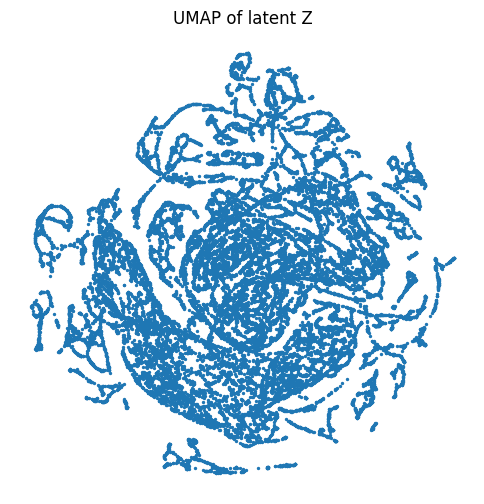

In [16]:
import umap
import matplotlib.pyplot as plt

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.3,
    n_components=2,
    random_state=0
)

Z_umap = reducer.fit_transform(Z)

plt.figure(figsize=(6,6))
plt.scatter(Z_umap[:,0], Z_umap[:,1], s=2)
plt.title("UMAP of latent Z")
plt.axis("off")
plt.show()

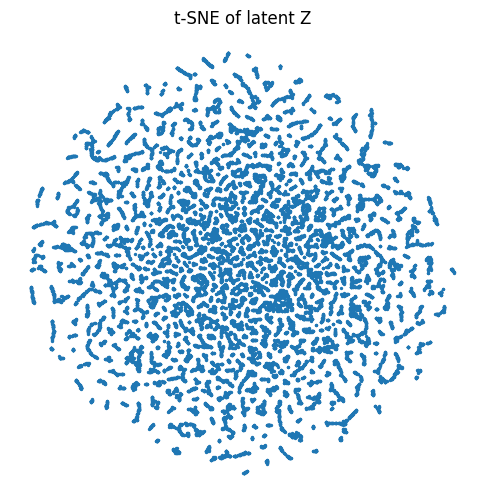

In [17]:
from sklearn.manifold import TSNE

Z_tsne = TSNE(n_components=2, perplexity=30, random_state=0).fit_transform(Z)

plt.figure(figsize=(6,6))
plt.scatter(Z_tsne[:,0], Z_tsne[:,1], s=2)
plt.title("t-SNE of latent Z")
plt.axis("off")
plt.show()

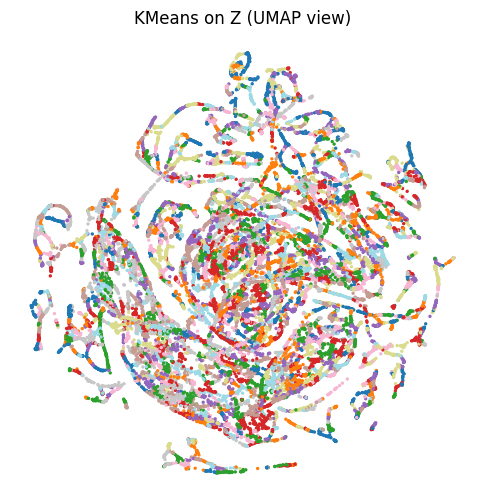

In [18]:
from sklearn.cluster import KMeans

k = 10  # 先试一个数
labels_km = KMeans(n_clusters=k, random_state=0).fit_predict(Z)
plt.figure(figsize=(6,6))
plt.scatter(Z_umap[:,0], Z_umap[:,1], c=labels_km, s=2, cmap="tab20")
plt.title("KMeans on Z (UMAP view)")
plt.axis("off")
plt.show()

In [19]:
import scanpy as sc
import anndata as ad

adata_z = ad.AnnData(Z)

In [20]:
sc.pp.neighbors(adata_z, n_neighbors=15, use_rep="X")
sc.tl.leiden(adata_z, resolution=0.5)

labels_leiden = adata_z.obs["leiden"].astype(int).values


/tmp/ipykernel_1297597/2313284263.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_z, resolution=0.5)


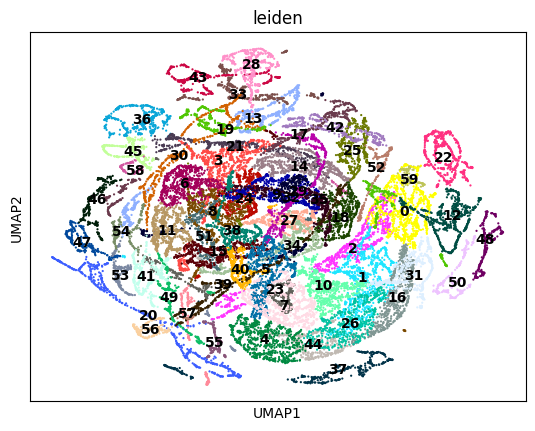

In [21]:
sc.tl.umap(adata_z)

sc.pl.umap(
    adata_z,
    color="leiden",
    size=10,
    legend_loc="on data"
)

In [22]:
adata.obs["leiden"]   # 原始聚类

33964601380598     6
33900176871163     3
33848637263605     5
34260954124030     9
34196529614579     5
                  ..
26736171425052     2
26663156981040     6
26555782798644     1
26495653256506    11
26414048877850     6
Name: leiden, Length: 24826, dtype: category
Categories (23, object): ['1', '2', '3', '4', ..., '20', '21', '22', '23']

In [23]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    adata.obs["leiden"].astype(str),
    adata_z.obs["leiden"].astype(str)
)
print("ARI (Z vs original Leiden):", ari)


ARI (Z vs original Leiden): 0.0014273545855717168


In [24]:
adata.obs["Z_leiden"] = adata_z.obs["leiden"].values


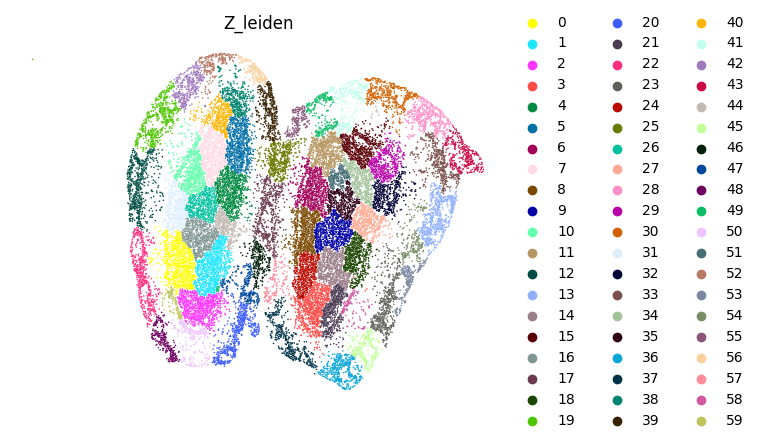

In [25]:
sc.pl.embedding(
    adata,
    basis="spatial",
    color="Z_leiden",
    size=5,
    frameon=False
)

In [26]:
import scanpy as sc
import numpy as np

# 假设 adata_z.X = Z，或者 adata.obsm["X_latent"] = Z
# 如果是 adata_z:
sc.pp.neighbors(adata_z, n_neighbors=15, use_rep="X")

for res in [0.05, 0.1, 0.2, 0.3, 0.5, 0.8, 1.0]:
    sc.tl.leiden(adata_z, resolution=res, key_added=f"leiden_{res}")
    n_clu = adata_z.obs[f"leiden_{res}"].nunique()
    print(f"res={res:<4}  n_clusters={n_clu}")


res=0.05  n_clusters=16
res=0.1   n_clusters=23
res=0.2   n_clusters=34
res=0.3   n_clusters=43
res=0.5   n_clusters=60
res=0.8   n_clusters=81
res=1.0   n_clusters=89


In [27]:
sc.tl.leiden(adata_z, resolution=0.02, key_added="Z_leiden")

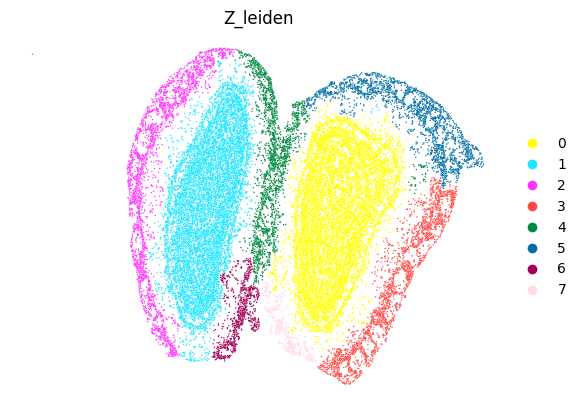

In [28]:
adata.obs["Z_leiden"] = adata_z.obs["Z_leiden"].values
sc.pl.embedding(adata, basis="spatial", color="Z_leiden", size=4, frameon=False, legend_loc="right margin")

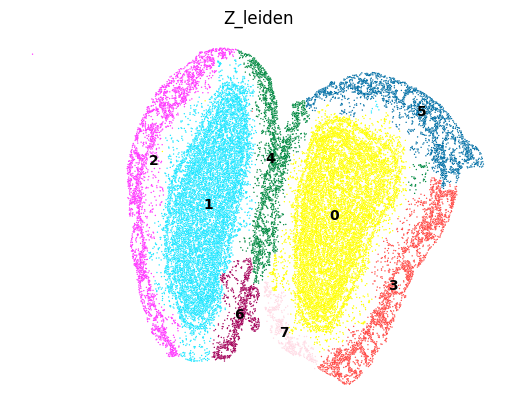

In [42]:
sc.pl.embedding(adata, basis="spatial", color="Z_leiden", size=4, frameon=False, legend_loc="on data")

In [29]:
# 如果你还没做过 normalize+log
adata_for_raw = adata.copy()
sc.pp.normalize_total(adata_for_raw, target_sum=1e4)
sc.pp.log1p(adata_for_raw)

adata.raw = adata_for_raw  # 把 log 表达存入 raw


In [30]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Z_leiden",
    groups=["0"],
    reference="rest",
    method="wilcoxon",
    use_raw=True
)


In [31]:
df0 = sc.get.rank_genes_groups_df(adata, group="0")
df0.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Calm2,6.019730,0.225495,1.747086e-09,0.000026
1,Ncdn,5.564674,0.274609,2.626427e-08,0.000247
2,Camk2b,5.366679,0.332461,8.019950e-08,0.000532
3,Ckb,5.337084,0.145938,9.445338e-08,0.000532
4,Vamp2,5.226145,0.203415,1.730804e-07,0.000812
5,Pcp4l1,5.057716,0.152175,4.243084e-07,0.001707
6,Gad1,4.993768,0.236445,5.921245e-07,0.002085
7,Snap25,4.894760,0.262963,9.842602e-07,0.003080
8,Pcp4,4.844378,0.332898,1.270086e-06,0.003252
9,Gpsm1,4.585518,0.190887,4.528612e-06,0.009811


In [55]:
# 导出为 txt 文件，去掉表头 (header=False) 和行号 (index=False)
df0['names'].head(100).to_csv("top100_genes_group0.txt", index=False, header=False)

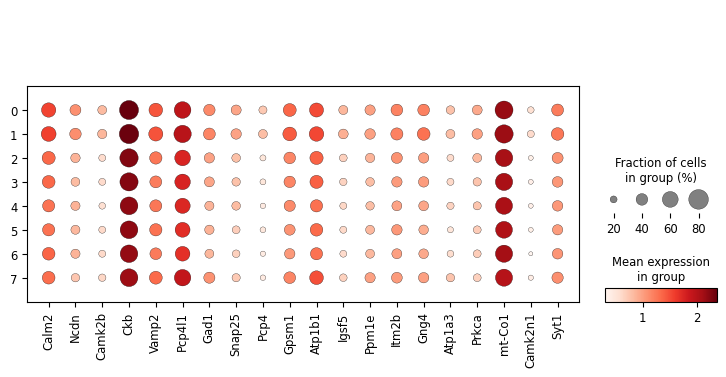

In [32]:
top0 = df0["names"].head(20).tolist()
sc.pl.dotplot(adata, var_names=top0, groupby="Z_leiden")

In [33]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Z_leiden",
    groups=["1"],
    reference="rest",
    method="wilcoxon",
    use_raw=True
)

In [34]:
df1 = sc.get.rank_genes_groups_df(adata, group="1")
df1.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Pcp4,9.590487,0.623153,8.766962e-22,3.527450e-18
1,Gng4,8.655866,0.433209,4.891863e-18,1.377793e-14
2,Gpsm1,7.247017,0.362619,4.260497e-13,1.090881e-09
3,Igsf5,7.135628,0.416877,9.634659e-13,2.261335e-09
4,Camk2n1,6.358397,0.493833,2.038700e-10,4.416923e-07
5,Ncdn,6.340885,0.333055,2.284492e-10,4.442686e-07
6,Camk2b,6.335233,0.377986,2.369829e-10,4.442686e-07
7,Atp1a1,6.325521,0.369280,2.523805e-10,4.442686e-07
8,Prkca,6.261039,0.341291,3.824198e-10,6.335796e-07
9,Kcnd2,6.199676,0.335421,5.657961e-10,8.853138e-07


In [ ]:
# 导出为 txt 文件，去掉表头 (header=False) 和行号 (index=False)
df1['names'].head(100).to_csv("top100_genes_group1.txt", index=False, header=False)

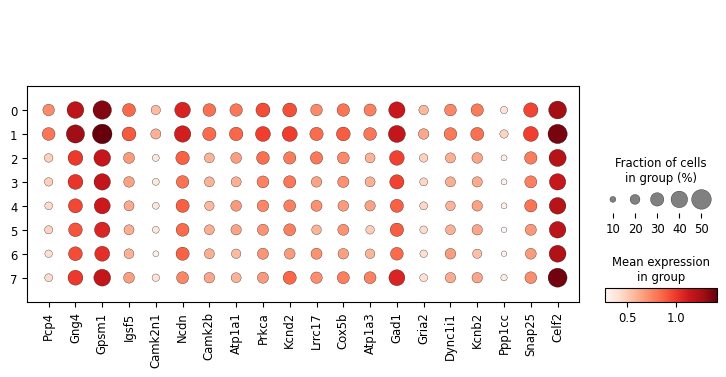

In [35]:
top1 = df1["names"].head(20).tolist()
sc.pl.dotplot(adata, var_names=top1, groupby="Z_leiden")


In [43]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Z_leiden",
    groups=["2"],
    reference="rest",
    method="wilcoxon",
    use_raw=True
)

In [44]:
df2 = sc.get.rank_genes_groups_df(adata, group="2")
df2.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Calb2,4.127255,0.454253,0.000037,0.282158
1,Apod,3.777873,0.472349,0.000158,0.409776
2,Lars2,3.771297,0.129796,0.000162,0.409776
3,Nrsn1,3.586219,0.425516,0.000336,0.649212
4,Glul,3.494718,0.402259,0.000475,0.835379
5,Gm42418,3.126532,0.074705,0.001769,1.000000
6,Gm10801,2.687437,0.984008,0.007200,1.000000
7,Gm26870,2.537738,0.342207,0.011157,1.000000
8,Cdk8,2.517480,0.071236,0.011820,1.000000
9,Apoe,2.393294,0.168048,0.016698,1.000000


In [54]:
# 导出为 txt 文件，去掉表头 (header=False) 和行号 (index=False)
df2['names'].head(100).to_csv("top100_genes_group2.txt", index=False, header=False)

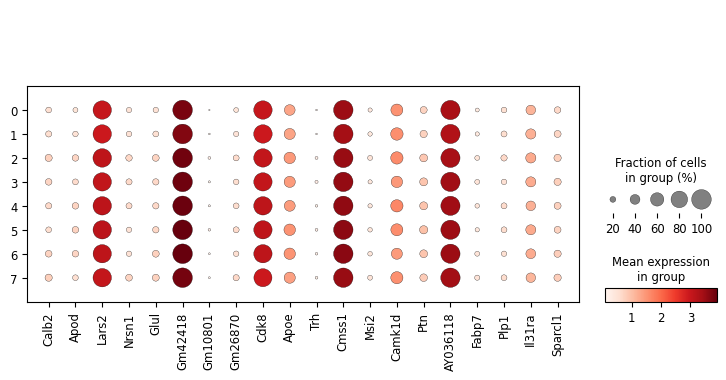

In [45]:
top2 = df2["names"].head(20).tolist()
sc.pl.dotplot(adata, var_names=top2, groupby="Z_leiden")

In [36]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Z_leiden",
    groups=["3"],
    reference="rest",
    method="wilcoxon",
    use_raw=True
)


In [37]:
df3 = sc.get.rank_genes_groups_df(adata, group="3")
df3.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,AY036118,5.522382,0.127474,3.344351e-08,0.000508
1,Gm42418,5.315278,0.110962,1.064947e-07,0.001000
2,Gm26917,5.229576,0.202119,1.698990e-07,0.001196
3,Cmss1,4.887142,0.094256,1.023104e-06,0.005340
4,Peak1,4.731540,0.195071,2.228229e-06,0.008965
5,Lars2,4.299303,0.086426,1.713365e-05,0.048257
6,Cdk8,3.992142,0.072812,6.547902e-05,0.153685
7,Zc3h7a,3.842367,0.266303,1.218534e-04,0.264000
8,Trh,2.844692,0.962816,4.445439e-03,1.000000
9,Cck,2.768627,0.385507,5.629300e-03,1.000000


In [56]:
# 导出为 txt 文件，去掉表头 (header=False) 和行号 (index=False)
df3['names'].head(100).to_csv("top100_genes_group3.txt", index=False, header=False)

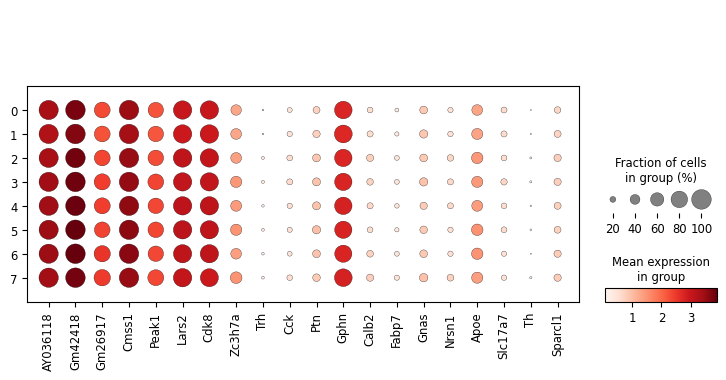

In [38]:
top3 = df3["names"].head(20).tolist()
sc.pl.dotplot(adata, var_names=top3, groupby="Z_leiden")

In [46]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Z_leiden",
    groups=["4"],
    reference="rest",
    method="wilcoxon",
    use_raw=True
)


In [47]:
df4 = sc.get.rank_genes_groups_df(adata, group="4")
df4.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Ptgds,9.633142,1.372795,5.793007e-22,1.631600e-17
1,Gm42418,7.866961,0.150133,3.633618e-15,5.117043e-11
2,Lars2,7.488652,0.168957,6.958449e-14,5.961823e-10
3,Cmss1,7.462851,0.136808,8.466995e-14,5.961823e-10
4,AY036118,7.289048,0.133590,3.121524e-13,1.758354e-09
5,Cdk8,7.241311,0.157788,4.443675e-13,2.085935e-09
6,Gm26917,5.728584,0.191637,1.012723e-08,3.348180e-05
7,Gphn,5.719259,0.101783,1.069896e-08,3.348180e-05
8,Peak1,4.903520,0.146191,9.413454e-07,2.344285e-03
9,Apod,3.641668,0.504629,2.708773e-04,3.051703e-01


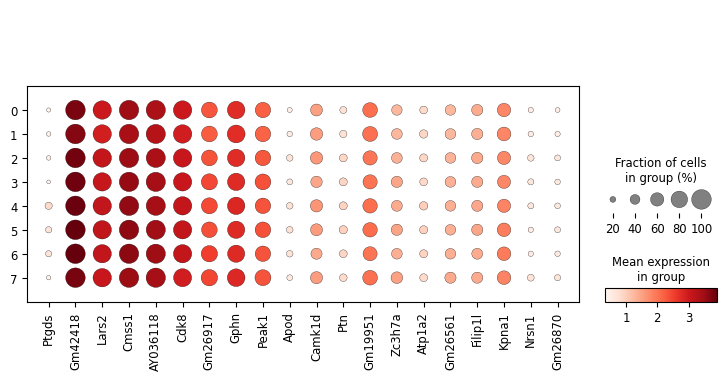

In [48]:
top4 = df4["names"].head(20).tolist()
sc.pl.dotplot(adata, var_names=top4, groupby="Z_leiden")

In [49]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Z_leiden",
    groups=["6"],
    reference="rest",
    method="wilcoxon",
    use_raw=True
)

In [50]:
df6 = sc.get.rank_genes_groups_df(adata, group="6")
df6.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Gm42418,5.964780,0.196424,2.449640e-09,0.000069
1,AY036118,5.724595,0.201074,1.036810e-08,0.000106
2,Cmss1,5.710265,0.192211,1.128007e-08,0.000106
3,Gm26917,5.639201,0.359650,1.708408e-08,0.000120
4,Lars2,4.705287,0.151850,2.535095e-06,0.014280
5,Cdk8,4.561173,0.148747,5.086856e-06,0.023879
6,Ptgds,3.484756,0.862528,4.925868e-04,1.000000
7,Peak1,2.987048,0.150225,2.816858e-03,1.000000
8,Kpna1,2.746538,0.205987,6.022797e-03,1.000000
9,Gphn,2.589401,0.026450,9.614316e-03,1.000000


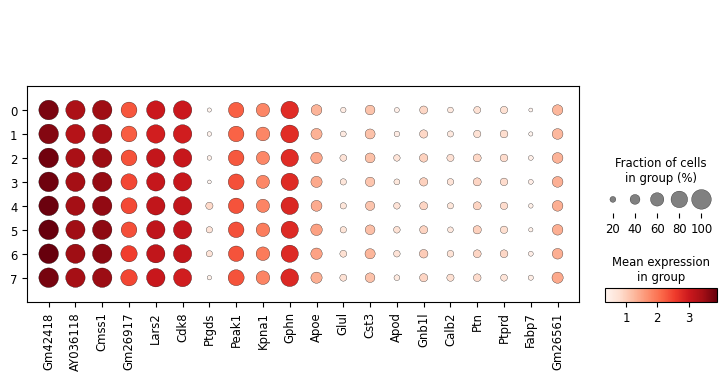

In [51]:
top6 = df6["names"].head(20).tolist()
sc.pl.dotplot(adata, var_names=top6, groupby="Z_leiden")

In [39]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Z_leiden",
    groups=["5"],
    reference="rest",
    method="wilcoxon",
    use_raw=True
)

In [40]:
df5 = sc.get.rank_genes_groups_df(adata, group="5")
df5.head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,Gm42418,8.630048,0.190965,6.132621e-18,1.727253e-13
1,Cmss1,8.286496,0.184447,1.166330e-16,1.642485e-12
2,AY036118,7.849418,0.172375,4.179722e-15,3.924062e-11
3,Lars2,7.782168,0.199085,7.129198e-15,5.019846e-11
4,Cdk8,6.842589,0.150253,7.777431e-12,4.381027e-08
5,Ptgds,5.868404,0.902958,4.400087e-09,1.549106e-05
6,Peak1,5.076293,0.187856,3.848687e-07,9.033190e-04
7,Apoe,4.413077,0.297008,1.019118e-05,1.435173e-02
8,Gphn,4.285332,0.047928,1.824667e-05,2.335989e-02
9,Zc3h7a,4.199161,0.310417,2.679061e-05,3.280685e-02


In [57]:
# 导出为 txt 文件，去掉表头 (header=False) 和行号 (index=False)
df5['names'].head(100).to_csv("top100_genes_group5.txt", index=False, header=False)

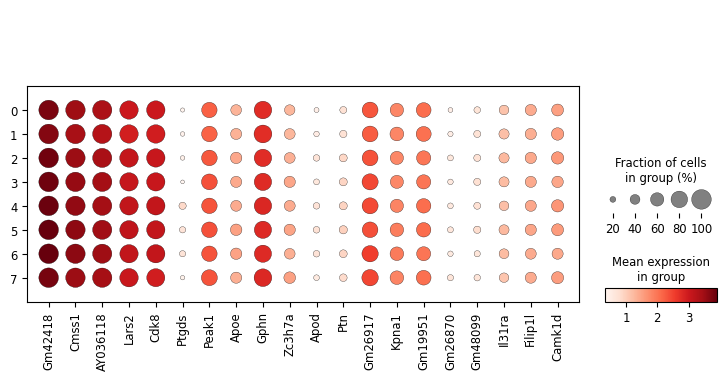

In [41]:
top5 = df5["names"].head(20).tolist()
sc.pl.dotplot(adata, var_names=top5, groupby="Z_leiden")